## 1. Introduction

## Bike-Sharing Demand: Descriptive Statistics & EDA
A small business analytics portfolio project using real-world data

Business question

How does bike rental demand vary across seasons, weather conditions, and working days, and what can these patterns tell us about demand planning?

## 2. Loading Required Libraries & Load the Dataset

In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/day.csv")

df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


## 2. Data Understanding and Initial Exploration

- Before analyzing bike rental demand, we first need to understand the dataset and check whether it is suitable for analysis.

- The dataset contains daily bike rental records. Each row represents one day, and the `cnt` column shows the total number of rentals on that day.

- We will inspect the dataset's size, column names, data types, missing values, and duplicate records before moving on to the main analysis.


In [38]:
# Inspect dataset dimensions and column information
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Dataset shape: (731, 16)

Column names:
['instant', 'dteday', 'season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  register

In [39]:
df.isnull().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [40]:
df.duplicated().sum()

np.int64(0)

In [41]:
df["cnt"].describe()

count     731.000000
mean     4504.348837
std      1937.211452
min        22.000000
25%      3152.000000
50%      4548.000000
75%      5956.000000
max      8714.000000
Name: cnt, dtype: float64

### Data Quality Check

- The dataset contains `731 rows and 16 columns`.
- No missing values or duplicate rows were found.
- This means we did not need to fill in missing values or remove duplicate records for this initial analysis.
- However, we will still need to consider whether the data and variables are suitable for each business question.
---


## 3. Distribution of Daily Bike Rental Demand

- Let's look at how many bikes people rented each day and how much the numbers changed from one day to another.

- **Business question:** Were daily rentals usually around the average, or did they change a lot from day to day?



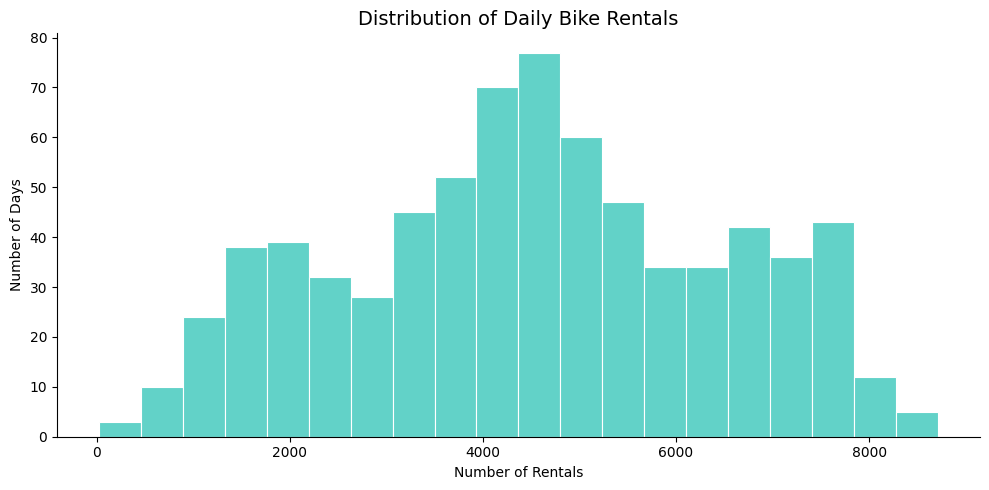

In [48]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="cnt",
    bins=20,
    color="#2EC4B6",
    edgecolor="white",
    linewidth=0.8
)

plt.title("Distribution of Daily Bike Rentals", fontsize=14)
plt.xlabel("Number of Rentals")
plt.ylabel("Number of Days")

sns.despine()
plt.tight_layout()
plt.show()


- Most days had around 4,000–5,000 rentals. However, daily rentals varied widely, ranging from 22 to 8,714.


---

## 4. Monthly Bike Rental Demand

Let's look at how bike rentals change from month to month. This helps us understand when demand is usually higher or lower during the year.

**Business question:** Which months have the highest and lowest average daily bike rentals?


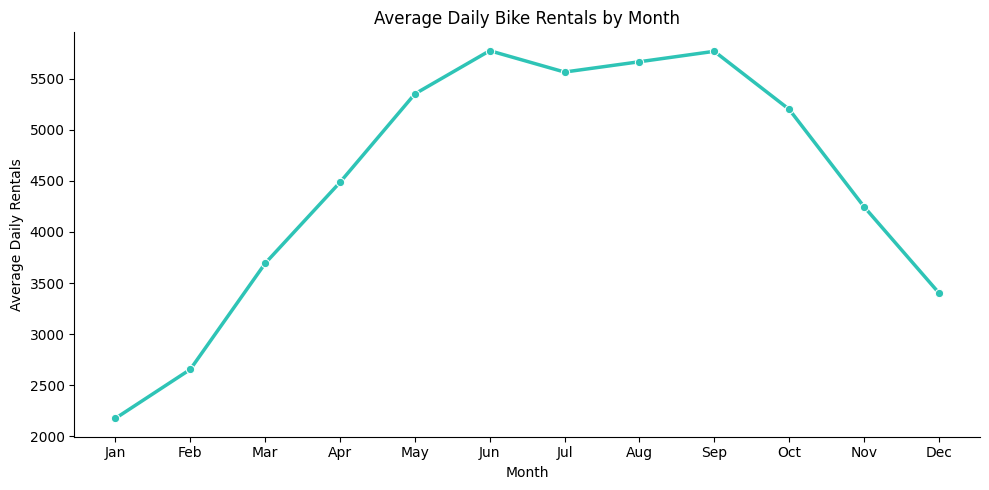

In [52]:

# Calculate average daily rentals for each month
monthly_avg = (
    df.groupby("mnth", as_index=False)["cnt"]
    .mean()
)

month_labels = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

plt.figure(figsize=(10, 5))

ax = sns.lineplot(
    data=monthly_avg,
    x="mnth",
    y="cnt",
    marker="o",
    linewidth=2.5,
    color="#2EC4B6"
)

plt.xticks(range(1, 13), month_labels)

plt.title("Average Daily Bike Rentals by Month")
plt.xlabel("Month")
plt.ylabel("Average Daily Rentals")

sns.despine()
plt.tight_layout()
plt.show()


- Average daily rentals increased from January to June, stayed high through September, and then declined toward December.
- January had the lowest average, at around 2,176 rentals per day, while June had the highest average, at around 5,772.



---

## 5. Bike Rentals on Working Days vs. Weekends

- Let's compare daily bike rentals on working days and weekends or holidays.

- **Business question:** Does bike rental demand differ between working days and non-working days?

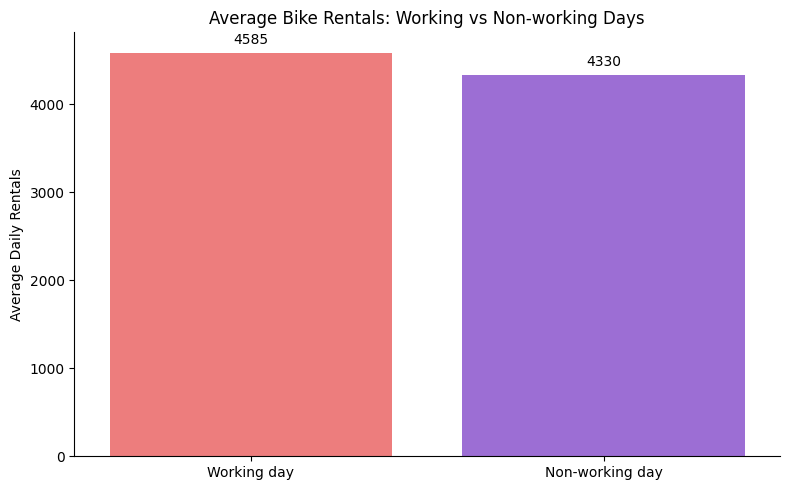

In [49]:

day_type_avg = (
    df.assign(
        day_type=df["workingday"].map({
            1: "Working day",
            0: "Non-working day"
        })
    )
    .groupby("day_type", as_index=False)["cnt"]
    .mean()
)

day_order = ["Working day", "Non-working day"]

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=day_type_avg,
    x="day_type",
    y="cnt",
    hue="day_type",
    order=day_order,
    hue_order=day_order,
    palette={
        "Working day": "#FF6B6B",
        "Non-working day": "#9B5DE5"
    },
    errorbar=None,
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=4)

plt.title("Average Bike Rentals: Working vs Non-working Days")
plt.xlabel("")
plt.ylabel("Average Daily Rentals")

sns.despine()
plt.tight_layout()
plt.show()



- Average daily rentals were higher on working days (4,585) than on non-working days (4,330). The difference was around 255 rentals per day.


---


## 6. Daily Bike Rentals by Season

- Let's compare average daily bike rentals across the four seasons.

- This can help us understand when demand is higher or lower during the year.

- **Business question:** Which season has the highest average daily bike rental demand?


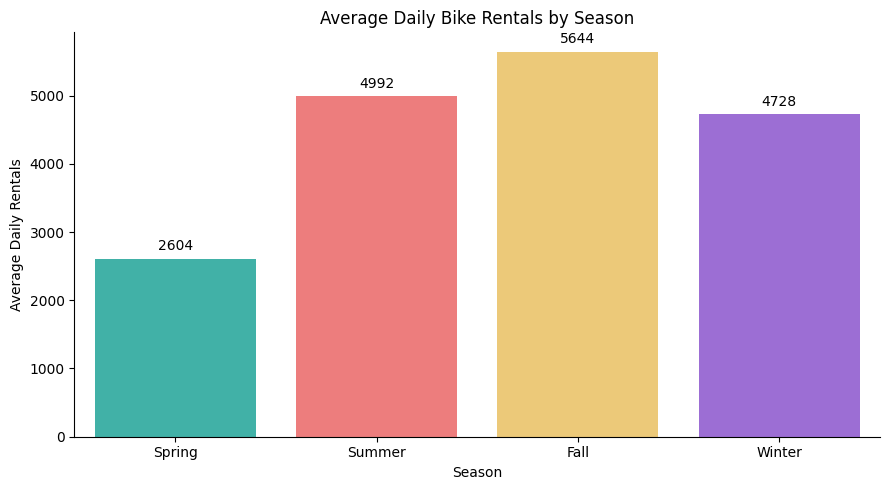

In [51]:

season_colors = {
    "Spring": "#2EC4B6",
    "Summer": "#FF6B6B",
    "Fall": "#FFD166",
    "Winter": "#9B5DE5"
}

season_order = ["Spring", "Summer", "Fall", "Winter"]

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=season_avg,
    x="season_name",
    y="cnt",
    hue="season_name",
    order=season_order,
    hue_order=season_order,
    palette=season_colors,
    errorbar=None,
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=4)

plt.title("Average Daily Bike Rentals by Season")
plt.xlabel("Season")
plt.ylabel("Average Daily Rentals")

sns.despine()
plt.tight_layout()
plt.show()


- Fall had the highest average daily rentals, at around 5,644, followed by summer (4,992) and winter (4,728). Spring had the lowest average, at around 2,604 rentals per day.


---


## 7. Bike Rentals by Weather

- Let's compare bike rentals under different weather conditions.
- This can help us understand whether people tend to rent more bikes when the weather is clear.
- **Business question:** How does average daily bike rental demand vary with weather conditions?


In [57]:
df["weathersit"].value_counts().reindex(
    [1, 2, 3, 4], fill_value=0
)

weathersit
1    463
2    247
3     21
4      0
Name: count, dtype: int64

- There were no observations in the severe weather category, so it does not appear in the chart.

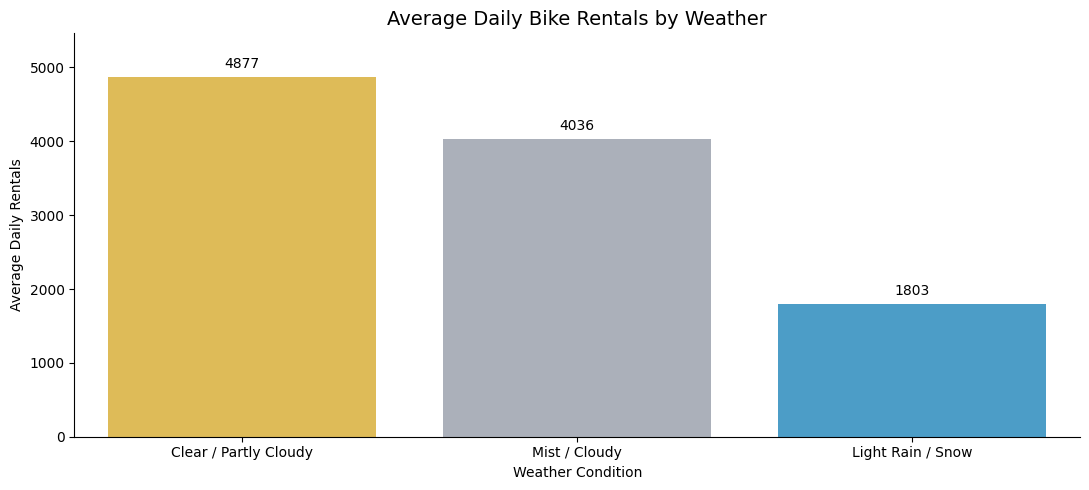

In [58]:

# Rename weather categories
weather_labels = {
    1: "Clear / Partly Cloudy",
    2: "Mist / Cloudy",
    3: "Light Rain / Snow",
    4: "Heavy Rain / Snow"
}

df["weather_name"] = df["weathersit"].map(weather_labels)

# Calculate average daily rentals
weather_avg = (
    df.groupby("weather_name", as_index=False)["cnt"]
    .mean()
)

# Keep only weather categories present in the data
weather_order = [
    "Clear / Partly Cloudy",
    "Mist / Cloudy",
    "Light Rain / Snow",
    "Heavy Rain / Snow"
]

weather_order = [
    w for w in weather_order
    if w in weather_avg["weather_name"].values
]

weather_avg["weather_name"] = pd.Categorical(
    weather_avg["weather_name"],
    categories=weather_order,
    ordered=True
)

weather_avg = weather_avg.sort_values("weather_name")

# Weather-based colors
weather_colors = {
    "Clear / Partly Cloudy": "#F4C542",
    "Mist / Cloudy": "#A8B0BC",
    "Light Rain / Snow": "#38A3DB",
    "Heavy Rain / Snow": "#5B3FAD"
}

# Plot
plt.figure(figsize=(11, 5))

ax = sns.barplot(
    data=weather_avg,
    x="weather_name",
    y="cnt",
    hue="weather_name",
    order=weather_order,
    hue_order=weather_order,
    palette=weather_colors,
    errorbar=None,
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=4)

plt.title("Average Daily Bike Rentals by Weather", fontsize=14)
plt.xlabel("Weather Condition")
plt.ylabel("Average Daily Rentals")
plt.xticks(rotation=0)
plt.margins(y=0.12)

sns.despine()
plt.tight_layout()
plt.show()


- Average daily rentals were highest in clear or partly cloudy weather (4,877), followed by mist or cloudy conditions (4,036). Light rain or snow had the lowest average, at around 1,803 rentals per day.

---


## 8. Casual vs. Registered Riders

- Let's compare casual and registered bike rentals on working and non-working days.
- **Business question:** Do casual and registered riders use the bike-sharing service differently depending on the day type?

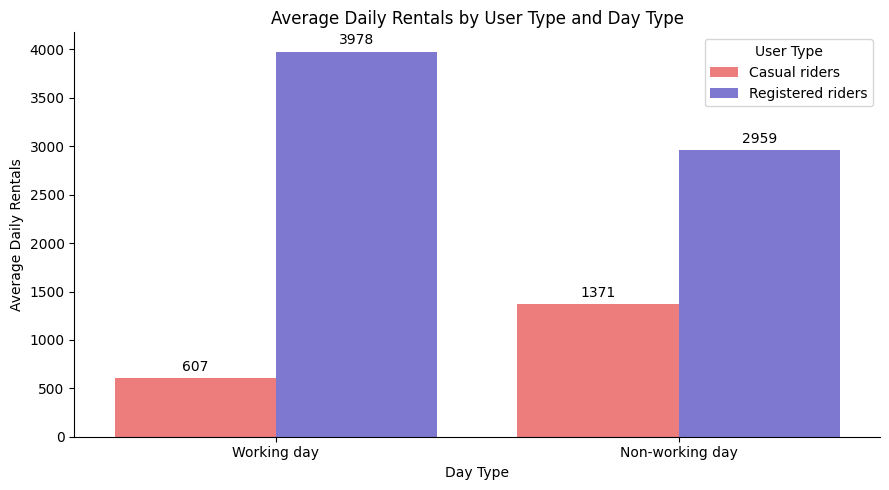

In [60]:
# Compare the two user groups by day type
user_type_by_day = (
    df.assign(
        day_type=df["workingday"].map({
            1: "Working day",
            0: "Non-working day"
        })
    )
    .groupby("day_type")[["casual", "registered"]]
    .mean()
    .reset_index()
    .melt(
        id_vars="day_type",
        var_name="user_type",
        value_name="avg_rentals"
    )
)

user_type_by_day["user_type"] = user_type_by_day["user_type"].map({
    "casual": "Casual riders",
    "registered": "Registered riders"
})

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=user_type_by_day,
    x="day_type",
    y="avg_rentals",
    hue="user_type",
    order=["Working day", "Non-working day"],
    hue_order=["Casual riders", "Registered riders"],
    palette={
        "Casual riders": "#FF6B6B",
        "Registered riders": "#7169E0"
    },
    errorbar=None
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.title("Average Daily Rentals by User Type and Day Type")
plt.xlabel("Day Type")
plt.ylabel("Average Daily Rentals")
plt.legend(title="User Type")

sns.despine()
plt.tight_layout()
plt.show()

- Registered riders averaged about 3,978 rentals on working days, compared with 2,959 on non-working days.
- Casual riders averaged 607 rentals on working days and 1,371 on non-working days.
- Registered riders used the service more on working days, while casual riders rented more bikes on non-working days.
- These differences may help the business plan its services and marketing for different customer groups. However, the chart does not explain why customers use the service.
---